# 計算物理学B 第五回：データの可視化

**野垣 康介、藤本 悠輝**  
2026/11/17

スライドに対応するNotebookです。GitHubから開いた場合は「ファイル」→「ドライブにコピーを保存」で自分用のコピーを作ります。パルサーの例では、Notebookと同じフォルダーにある `pulsar.csv` を使います。Google Colabでは、GitHubで同じフォルダーを開いてCSVをダウンロードし、ランタイムにアップロードしてください。

このNotebookの図をPDF/PNGファイルとしてまとめて作り直す場合は、`2026/week5` で `python make_figures.py` を実行します。CSVの出典は[ATNF Pulsar Catalogue](https://www.atnf.csiro.au/research/pulsar/psrcat/)です。


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import animation
from IPython.display import HTML
from scipy.special import jv


`fig, ax = plt.subplots()` は、図全体を入れる`fig`と、グラフを描く領域`ax`を作ります。`ax.plot`や`ax.set_xlabel`のように`ax`を通す書き方は、操作するグラフを明示できます。`plt.plot`や`plt.xlabel`は現在選ばれているグラフを操作する書き方です。どちらも使えますが、複数のグラフを並べるときは`ax`を使う方法が分かりやすくなります。


In [2]:
params = {
    'legend.fontsize': 10,
    'axes.labelsize': 12,
    'axes.titlesize': 13,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'xtick.direction': 'in',
    'ytick.direction': 'in',
}
plt.rcParams.update(params)


Matplotlibの設定項目については[公式ドキュメント](https://matplotlib.org/stable/users/explain/customizing.html)を参照してください。


## 折れ線グラフ

まず、$x=0$から$10$までの点で$\cos x$を計算します。点が少ない場合と多い場合を比べます。


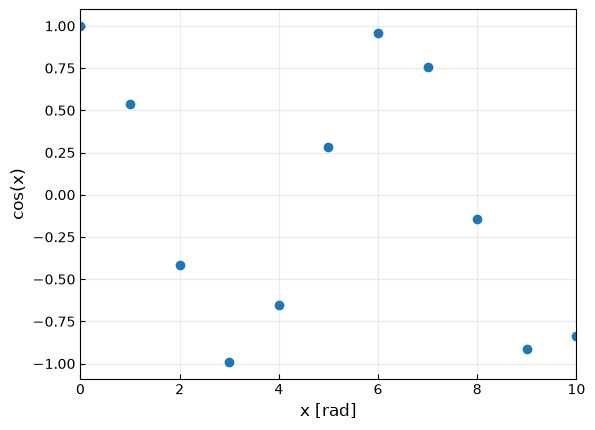

In [3]:
# 11点で関数値を計算し、点として示す
numpoints = 11
x = np.linspace(0, 10, numpoints)
y = np.cos(x)

fig, ax = plt.subplots()
ax.plot(x, y, 'o')
ax.set(xlabel='x [rad]', ylabel='cos(x)', xlim=(0, 10))
ax.grid(alpha=0.25)
plt.show()


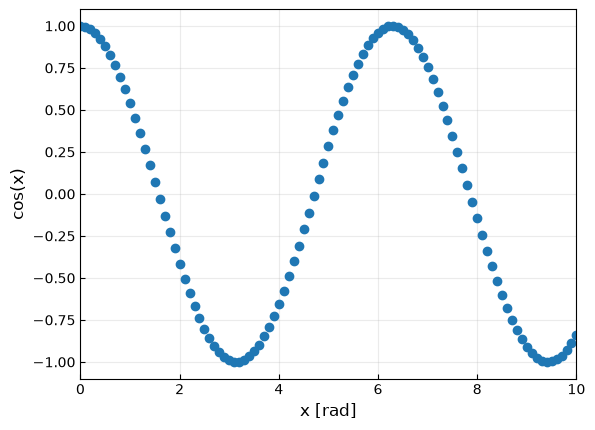

In [4]:
# 101点に増やす
numpoints = 101
x = np.linspace(0, 10, numpoints)
y = np.cos(x)

fig, ax = plt.subplots()
ax.plot(x, y, 'o')
ax.set(xlabel='x [rad]', ylabel='cos(x)', xlim=(0, 10))
ax.grid(alpha=0.25)
plt.show()


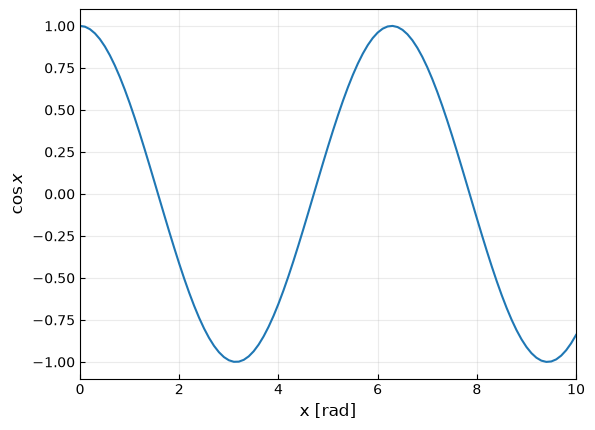

In [5]:
# 点が十分に多ければ、線分でつないで連続的な変化を表せる
fig, ax = plt.subplots()
ax.plot(x, y)
ax.set(xlabel='x [rad]', ylabel=r'$\cos x$', xlim=(0, 10))
ax.grid(alpha=0.25)
plt.show()


データ点が少なすぎると、関数の変化を正しく表しにくくなります。次の図は意図的に7点だけを線で結んだ例です。


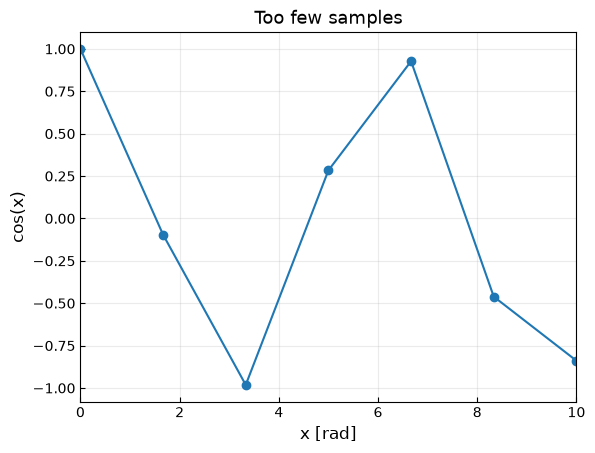

In [6]:
x_sparse = np.linspace(0, 10, 7)
y_sparse = np.cos(x_sparse)
fig, ax = plt.subplots()
ax.plot(x_sparse, y_sparse, 'o-')
ax.set(title='Too few samples', xlabel='x [rad]', ylabel='cos(x)', xlim=(0, 10))
ax.grid(alpha=0.25)
plt.show()


軸のラベルがないと、何を示す図なのか分からなくなります。次は軸ラベルを意図的に省いた例です。


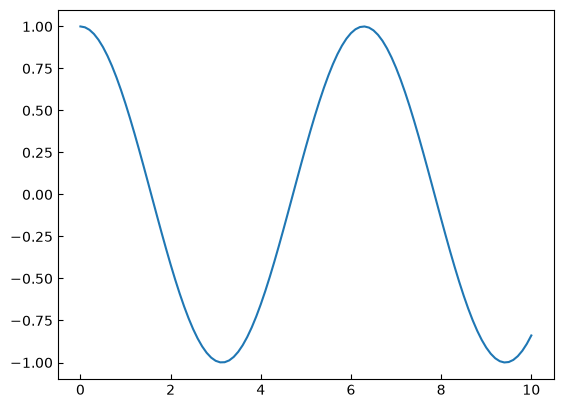

In [7]:
fig, ax = plt.subplots()
ax.plot(x, y)
# この例では、悪い例を示すため軸ラベルを付けない
plt.show()


複数のデータを同じ色・線種で示すと区別しにくくなります。凡例だけでは十分でない例です。


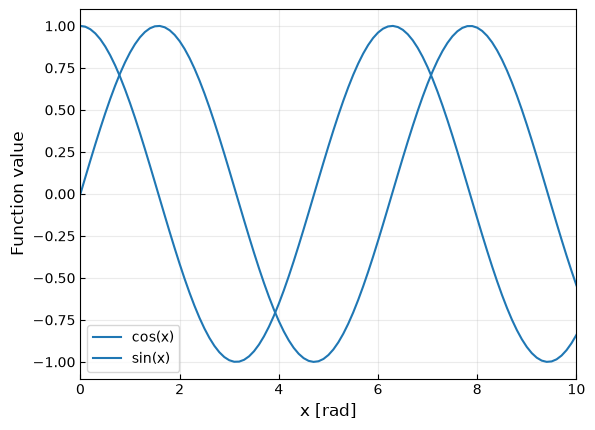

In [8]:
x = np.linspace(0, 10, 101)
fig, ax = plt.subplots()
ax.plot(x, np.cos(x), color='C0', linestyle='-', label='cos(x)')
ax.plot(x, np.sin(x), color='C0', linestyle='-', label='sin(x)')
ax.set(xlabel='x [rad]', ylabel='Function value', xlim=(0, 10))
ax.legend()
ax.grid(alpha=0.25)
plt.show()


## 複数の曲線

線の色と線種を変え、凡例を加えると複数のデータを読み取りやすくなります。図の保存には `savefig` を使います。


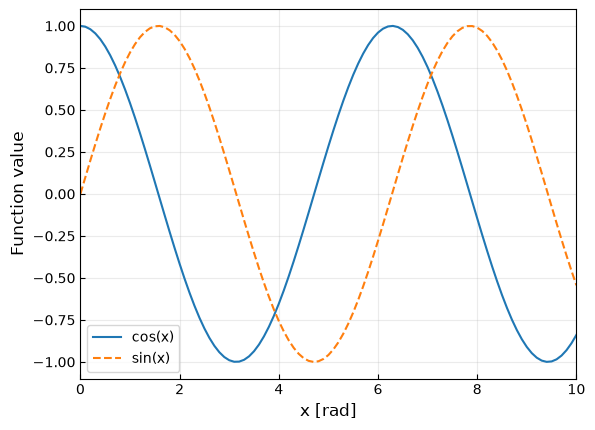

In [9]:
x = np.linspace(0, 10, 101)
fig, ax = plt.subplots()
ax.plot(x, np.cos(x), color='C0', linestyle='-', label='cos(x)')
ax.plot(x, np.sin(x), color='C1', linestyle='--', label='sin(x)')
ax.set(xlabel='x [rad]', ylabel='Function value', xlim=(0, 10))
ax.legend()
ax.grid(alpha=0.25)
fig.savefig('graph.pdf', bbox_inches='tight')
plt.show()


## 散布図

各測定点を個別の点として描くときは散布図を使います。次は相関を持つように作った**模擬データ**です。実測値ではありません。


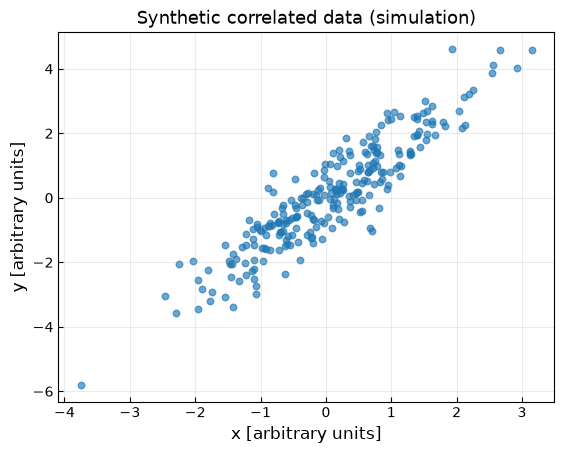

In [10]:
rng = np.random.default_rng(2026)
x_simulated = rng.normal(size=250)
y_simulated = 1.4 * x_simulated + 0.65 * rng.normal(size=x_simulated.size)

fig, ax = plt.subplots()
ax.scatter(x_simulated, y_simulated, s=22, alpha=0.65)
ax.set(title='Synthetic correlated data (simulation)',
       xlabel='x [arbitrary units]', ylabel='y [arbitrary units]')
ax.grid(alpha=0.25)
plt.show()


### パルサーの周期と周期微分

`pulsar.csv` はATNF Pulsar Catalogueから取得した表です。周期$P$と周期微分$\dot P$を対数軸に描くため、両方が有限で正の行を選びます。$\dot P\leq0$の行はデータの誤りと決めつけず、対数表示の対象外として扱います。

破線の表面磁場$B$と点線の特性年齢$\tau_c$は、正の内因性$\dot P$を仮定した単純な双極子放射模型による目安です。実測値やパルサーの真の年齢ではありません。観測された$\dot P$には運動学的効果などが含まれることもあります。


In [11]:
raw = pd.read_csv('pulsar.csv')
period_data = raw[['P0', 'P1']].apply(pd.to_numeric, errors='coerce').to_numpy()
finite_pair = np.isfinite(period_data).all(axis=1)
valid = finite_pair & (period_data > 0).all(axis=1)

p1 = pd.to_numeric(raw['P1'], errors='coerce').to_numpy()
finite_p1 = np.isfinite(p1)
print(f"Rows: {len(raw)}")
print(f"P1 > 0: {np.count_nonzero(finite_p1 & (p1 > 0))}")
print(f"P1 < 0: {np.count_nonzero(finite_p1 & (p1 < 0))}")
print(f"P1 = 0: {np.count_nonzero(finite_p1 & (p1 == 0))}")
print(f"P1 missing or non-finite: {np.count_nonzero(~finite_p1)}")
print(f"Selected for log plot (finite P0, P1 > 0): {np.count_nonzero(valid)}")

df = raw.loc[valid].copy()
df.head()


Rows: 4303
P1 > 0: 2746
P1 < 0: 68
P1 = 0: 4
P1 missing or non-finite: 1485
Selected for log plot (finite P0, P1 > 0): 2746


,NAME,P0,P1
0,J0002+6216,0.115364,5.970000e-15
1,J0006+1834,0.693748,2.100000e-15
2,J0007+7303,0.315873,3.600000e-13
4,J0012+5431,3.025301,1.280000e-16
5,B0011+47,1.240699,5.640000e-16


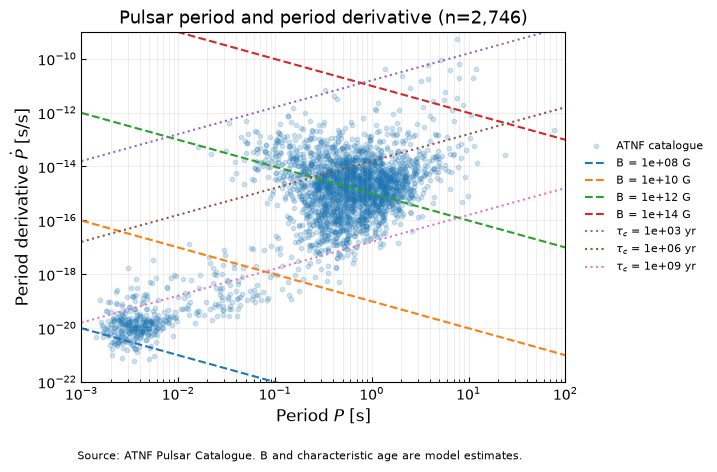

In [12]:
P = df['P0'].to_numpy()
Pdot = df['P1'].to_numpy()
assert np.isfinite(P).all() and np.isfinite(Pdot).all()
assert (P > 0).all() and (Pdot > 0).all()

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(P, Pdot, color='C0', alpha=0.2, s=10, label='ATNF catalogue')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(1e-3, 1e2)
ax.set_ylim(1e-22, 1e-9)
ax.set_xlabel(r'Period $P$ [s]')
ax.set_ylabel(r'Period derivative $\dot{P}$ [s/s]')
ax.set_title(f'Pulsar period and period derivative (n={len(df):,})')
ax.grid(True, which='both', alpha=0.2)

P_values = np.logspace(-3, 2, 500)
for B in (1e8, 1e10, 1e12, 1e14):
    Pdot_values = (B / 3.2e19)**2 / P_values
    ax.plot(P_values, Pdot_values, '--', label=f'B = {B:.0e} G')

seconds_per_year = 365.25 * 24 * 60 * 60
for tau_years in (1e3, 1e6, 1e9):
    Pdot_values = P_values / (2 * tau_years * seconds_per_year)
    ax.plot(P_values, Pdot_values, ':', label=rf'$\tau_c$ = {tau_years:.0e} yr')

ax.legend(loc='center left', bbox_to_anchor=(1.02, 0.5), fontsize=8, frameon=False)
fig.subplots_adjust(right=0.73, bottom=0.18)
fig.text(0.12, 0.025, 'Source: ATNF Pulsar Catalogue. B and characteristic age are model estimates.', fontsize=8)
plt.show()


## 等高線図と密度プロット

2変数関数の例として、無次元化した電気双極子ポテンシャルを考えます。正電荷を$(-2,0)$、負電荷を$(2,0)$に置き、

$$V_{\rm dip}(x,y)=\frac{1}{r_+}-\frac{1}{r_-},\qquad
r_+=\sqrt{(x+2)^2+y^2},\quad r_-=\sqrt{(x-2)^2+y^2}.$$

`meshgrid`は、x座標とy座標から平面上の全ての座標の組を作ります。`hypot`で各電荷からの距離を求め、`divide`の`where`で電荷中心付近の0除算を避けます。`masked_where`は電荷から距離$0.25$未満を図から隠します。

密度図の色範囲は$-1.5$から$1.5$、3次元曲面は$-5$から$5$に固定します。範囲外の値は色の端に飽和するため、色だけで値の違いを読み取れない場合があります。


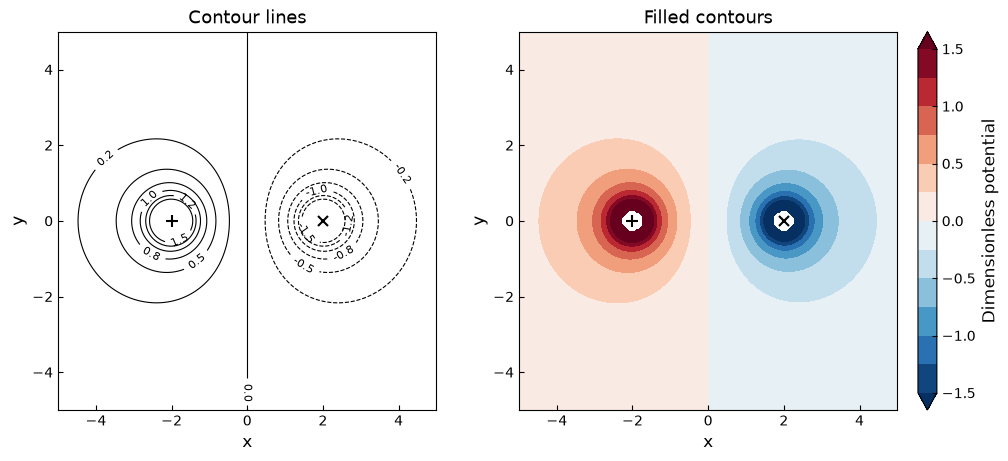

In [13]:
x = np.linspace(-5, 5, 200)
y = np.linspace(-5, 5, 200)
X, Y = np.meshgrid(x, y)
r_plus = np.hypot(X + 2, Y)
r_minus = np.hypot(X - 2, Y)
outside = (r_plus >= 0.25) & (r_minus >= 0.25)
V_plus = np.divide(1.0, r_plus, out=np.zeros_like(r_plus), where=r_plus >= 0.25)
V_minus = np.divide(1.0, r_minus, out=np.zeros_like(r_minus), where=r_minus >= 0.25)
Vdip = np.ma.masked_where(~outside, V_plus - V_minus)
assert Vdip.shape == (200, 200) and np.ma.getmaskarray(Vdip).any()

levels = np.linspace(-1.5, 1.5, 13)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.5), constrained_layout=True)
contours = ax1.contour(X, Y, Vdip, levels=levels, colors='black', linewidths=0.8)
ax1.clabel(contours, inline=True, fontsize=8, fmt='%.1f')
ax1.set_title('Contour lines')
filled = ax2.contourf(X, Y, Vdip, levels=levels, cmap='RdBu_r', extend='both')
fig.colorbar(filled, ax=ax2, label='Dimensionless potential')
ax2.set_title('Filled contours')
for ax in (ax1, ax2):
    ax.set(xlabel='x', ylabel='y', xlim=(-5, 5), ylim=(-5, 5), aspect='equal')
    ax.plot(-2, 0, 'k+', ms=9, mew=1.5)
    ax.plot(2, 0, 'kx', ms=7, mew=1.5)
plt.show()


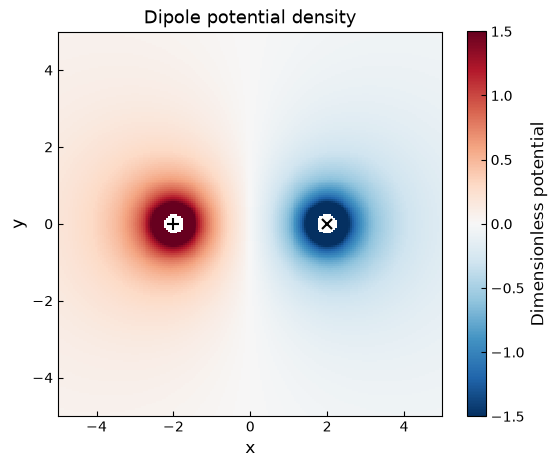

In [14]:
fig, ax = plt.subplots(figsize=(6.2, 5))
image = ax.imshow(Vdip, origin='lower', extent=[-5, 5, -5, 5],
                  cmap='RdBu_r', vmin=-1.5, vmax=1.5, interpolation='nearest')
fig.colorbar(image, ax=ax, label='Dimensionless potential')
ax.plot(-2, 0, 'k+', ms=9, mew=1.5)
ax.plot(2, 0, 'kx', ms=7, mew=1.5)
ax.set(xlabel='x', ylabel='y', title='Dipole potential density',
       xlim=(-5, 5), ylim=(-5, 5), aspect='equal')
plt.show()


## 3次元プロット

同じポテンシャルを曲面として描き、底面には等高線を重ねます。z軸と曲面の色範囲は$-5$から$5$です。色は値の範囲を示す補助であり、軸の高さも合わせて読みます。


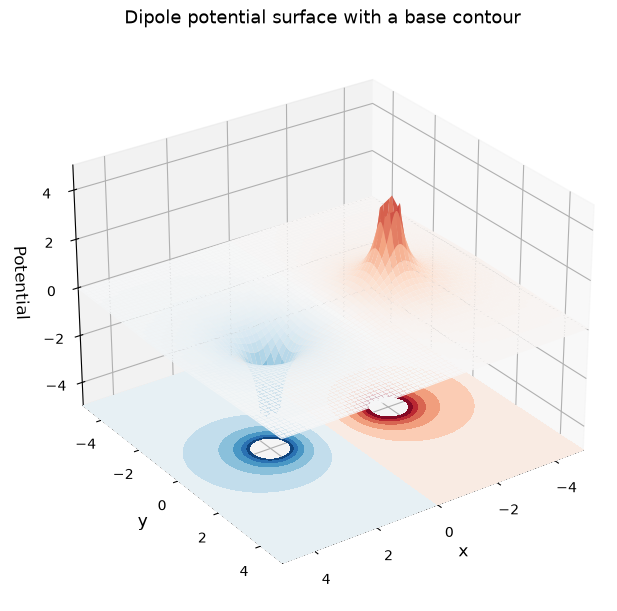

In [15]:
fig = plt.figure(figsize=(8, 6), constrained_layout=True)
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(X, Y, Vdip, rstride=3, cstride=3, cmap='RdBu_r',
                vmin=-5, vmax=5, linewidth=0, antialiased=True)
ax.contourf(X, Y, Vdip, zdir='z', offset=-5,
            levels=np.linspace(-1.5, 1.5, 13), cmap='RdBu_r', vmin=-1.5, vmax=1.5)
ax.set(xlim=(-5, 5), ylim=(-5, 5), zlim=(-5, 5), xlabel='x', ylabel='y', zlabel='Potential')
ax.set_title('Dipole potential surface with a base contour')
ax.view_init(elev=28, azim=55)
plt.show()


## 実習：第一種Bessel関数

`scipy.special.jv` を使い、$J_v(x)$を$v=0,1,2,3$について$x=0$から$20$まで描きます。線種は順に`-`、`--`、`:`、`-.`とし、凡例を付けてください。提出用の図はPDFで保存します。線種の見本は配布スライドの実習図を参照してください。


## 発展：フラクタル

マンデルブロ集合、コッホ曲線、バーンズリーのシダ、シェルピンスキーのギャスケット、ジュリア集合などから一つ選び、調べて図示してください。マンデルブロ集合の例図は配布スライドを参照してください。`make_figures.py`が出力するPNGは反復回数に上限を設けた近似例で、解像度と反復回数に依存します。


## アニメーション：サイクロイド

サイクロイドを円の回転角$\theta$でパラメータ表示します。$\theta$は角度パラメータであり、角速度を1と置けば時間としても扱えます。理想的な一様重力の下で、抵抗がなく静止から出発し、固定された2点を適切な向きの弧で結ぶ場合に、サイクロイドは最速降下曲線になります。


このアニメーションは角度を等間隔に進めた幾何学的な表示です。重力下の降下運動を計算したものではなく、表示間隔は物理的な時間を表しません。

In [16]:
radius = 1
theta = np.linspace(0, 5 * np.pi, 100)
x = radius * (theta - np.sin(theta))
y = radius * (1 - np.cos(theta))
center_x = radius * theta
center_y = np.full_like(theta, radius)

fig, ax = plt.subplots()
ax.set_aspect('equal')
ax.set_xlim(0, x[-1])
ax.set_ylim(-0.5, 2 * radius + 0.5)
ax.set_title('Cycloid animation')
cycloid_line, = ax.plot([], [], 'C0', lw=2)
circle_line, = ax.plot([], [], 'k--')
point, = ax.plot([], [], 'ro', markersize=6)

def init():
    cycloid_line.set_data([], [])
    point.set_data([], [])
    circle_line.set_data([], [])
    return cycloid_line, point, circle_line

def update(frame):
    cycloid_line.set_data(x[:frame + 1], y[:frame + 1])
    point.set_data([x[frame]], [y[frame]])
    angle = np.linspace(0, 2 * np.pi, 100)
    circle_line.set_data(center_x[frame] + radius * np.cos(angle),
                         center_y[frame] + radius * np.sin(angle))
    return cycloid_line, point, circle_line

ani = animation.FuncAnimation(fig, update, frames=len(theta), init_func=init,
                              interval=70, blit=False)
plt.close(fig)
HTML(ani.to_jshtml())
